In [1]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.img_tiles as cimgt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from matplotlib.colors import LogNorm, Normalize
import proplot as plot
import rioxarray
import xarray as xr
import numpy as np
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import warnings
import geopandas as gpd
plot.rc['cmap.discrete'] = False
import os
warnings.filterwarnings("ignore")

ERROR 1: PROJ: proj_create_from_database: Open of /home/alessandrom/anaconda3/envs/bias_correction_conda/share/proj failed
/home/alessandrom/anaconda3/envs/bias_correction_conda/lib/python3.10/site-packages/gribapi/__init__.py:23: UserWarning: ecCodes 2.31.0 or higher is recommended. You are running version 2.16.0
  warnings.warn(


In [2]:
country = 'cuba'

In [3]:
geom_path = f'../world_map/ne_50m_admin_0_countries.shp'
geometries = gpd.read_file(geom_path)
geometries = geometries[geometries['NAME_EN'] == f'{country.capitalize()}']['geometry']

In [4]:
model = 'CNRM-ESM2-1'
exp = 'ssp370'
start = '2030' 
end = '2049'

In [5]:
month= 1

in_path   = f'../data/atlas_data/{country}/{exp}/{model}/10m_wind_{country}_m{month}_{exp}_{start}_{end}.nc'
            
months_names = ['January','February','March','April','May','June','July',
                'August','September','October','November','December']
xdf = xr.open_mfdataset(in_path).sortby('latitude')

In [6]:
#Annual Plot: Opening the monthly files and concatenate, averaging.

#files_list = []
#for month in range(1,13):
    #in_path   = f'../data/atlas_data/{country}/{exp}/{model}/10m_wind_integrated_{country}_m{month}.nc'
#    month_file = xr.open_mfdataset(in_path).assign(month=month)
#    files_list.append(month_file)
#xdf = xr.concat(files_list,dim='month').mean('month')

In [7]:
output_path = f'../data/figures/{country}/'
output_dir = os.path.dirname(output_path)
os.makedirs(output_dir, exist_ok=True)

In [8]:
import cartopy.io.img_tiles as cimgt

class StadiaStamen(cimgt.Stamen):
    def _image_url(self, tile):
         x,y,z = tile
         url = f"https://tiles.stadiamaps.com/tiles/stamen_terrain_background/{z}/{x}/{y}.png?api_key=16f26ea8-2565-4da3-972a-49888d65b1e8"
         return url
        
class StadiaMap(cimgt.GoogleTiles):
    def __init__(self, style='alidade_smooth'):
        self._style = style
        super().__init__()

    def _image_url(self, tile):
        x, y, z = tile
        url = f"https://tiles.stadiamaps.com/tiles/{self._style}/{z}/{x}/{y}.png?api_key=16f26ea8-2565-4da3-972a-49888d65b1e8"
        return url

### Wind Direction

In [9]:
def draw_dir(xdf, ax, vmin, vmax, cmap, legend=False, label=None, title=None, suptitle=None, orient='vertical'):

    # Add features to the map

    ax.add_feature(cfeature.LAKES, edgecolor='black', facecolor='light blue')
    ax.add_feature(cfeature.OCEAN, edgecolor='light blue')
    ax.add_feature(cfeature.RIVERS, edgecolor='light blue')
    ax.add_feature(cfeature.COASTLINE, edgecolor='black', linewidth=1.2)
    ax.add_feature(cfeature.BORDERS, edgecolor='black', linewidth=1.2)

    xdf.rio.set_spatial_dims(x_dim="longitude", y_dim="latitude", inplace=True)
    xdf.rio.write_crs("epsg:4326", inplace=True)
    
    cbar_kwargs = {
        'orientation': 'vertical',
        'shrink': 0.25,
        'aspect': 50,
        'pad': 2,
        'label': label,
        'labelsize': 11,
        
    } if legend else None
    im = xr.plot.pcolormesh(xdf, cmap=cmap, # cyclic colorbar is useful for wind direction
                            ax = ax, 
                            #norm=LogNorm(),
                            vmin=vmin, vmax=vmax,
                            add_colorbar=legend, 
                            add_labels=False, 
                            cbar_kwargs=cbar_kwargs, 
                       )

    if orient == 'horizontal':
        cbar = im.colorbar
        cbar.ax.tick_params(axis='y', rotation=90)
        
    # Add longitude-latitude grid
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
    gl.xlabels_top = False
    gl.ylabels_right = False
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER

    lat_min = np.min(xdf.latitude.values)
    lat_max = np.max(xdf.latitude.values)
    lon_min = np.min(xdf.longitude.values)
    lon_max = np.max(xdf.longitude.values)

    ax.set_extent([lon_min-0.5, lon_max+0.5, lat_min-0.5, lat_max+0.5], crs=ccrs.PlateCarree())
    ax.set_title(title, fontsize=14)
    fig.suptitle(suptitle,fontsize=17)

In [10]:
xdf

<xarray.Dataset>
Dimensions:         (latitude: 3305, longitude: 8889)
Coordinates:
  * latitude        (latitude) float32 19.86 19.86 19.86 ... 23.18 23.19 23.19
  * longitude       (longitude) float32 -84.89 -84.89 -84.88 ... -74.14 -74.14
Data variables:
    u10_integrated  (latitude, longitude) float64 dask.array<chunksize=(3305, 8889), meta=np.ndarray>
    v10_integrated  (latitude, longitude) float64 dask.array<chunksize=(3305, 8889), meta=np.ndarray>
    wds_integrated  (latitude, longitude) float64 dask.array<chunksize=(3305, 8889), meta=np.ndarray>
    dir_integrated  (latitude, longitude) float64 dask.array<chunksize=(3305, 8889), meta=np.ndarray>
    wds_delta       (latitude, longitude) float64 dask.array<chunksize=(3305, 8889), meta=np.ndarray>
    u10_delta       (latitude, longitude) float64 dask.array<chunksize=(3305, 8889), meta=np.ndarray>
    v10_delta       (latitude, longitude) float64 dask.array<chunksize=(3305, 8889), meta=np.ndarray>
    dir_delta       (latitude, longitude) float64 dask.array<chunksize=(3305, 8889), meta=np.ndarray>
Attributes:
    units:        m s-1, [°]
    description:  Wind Speed measurement height: 10m. Wind Direction measurem...

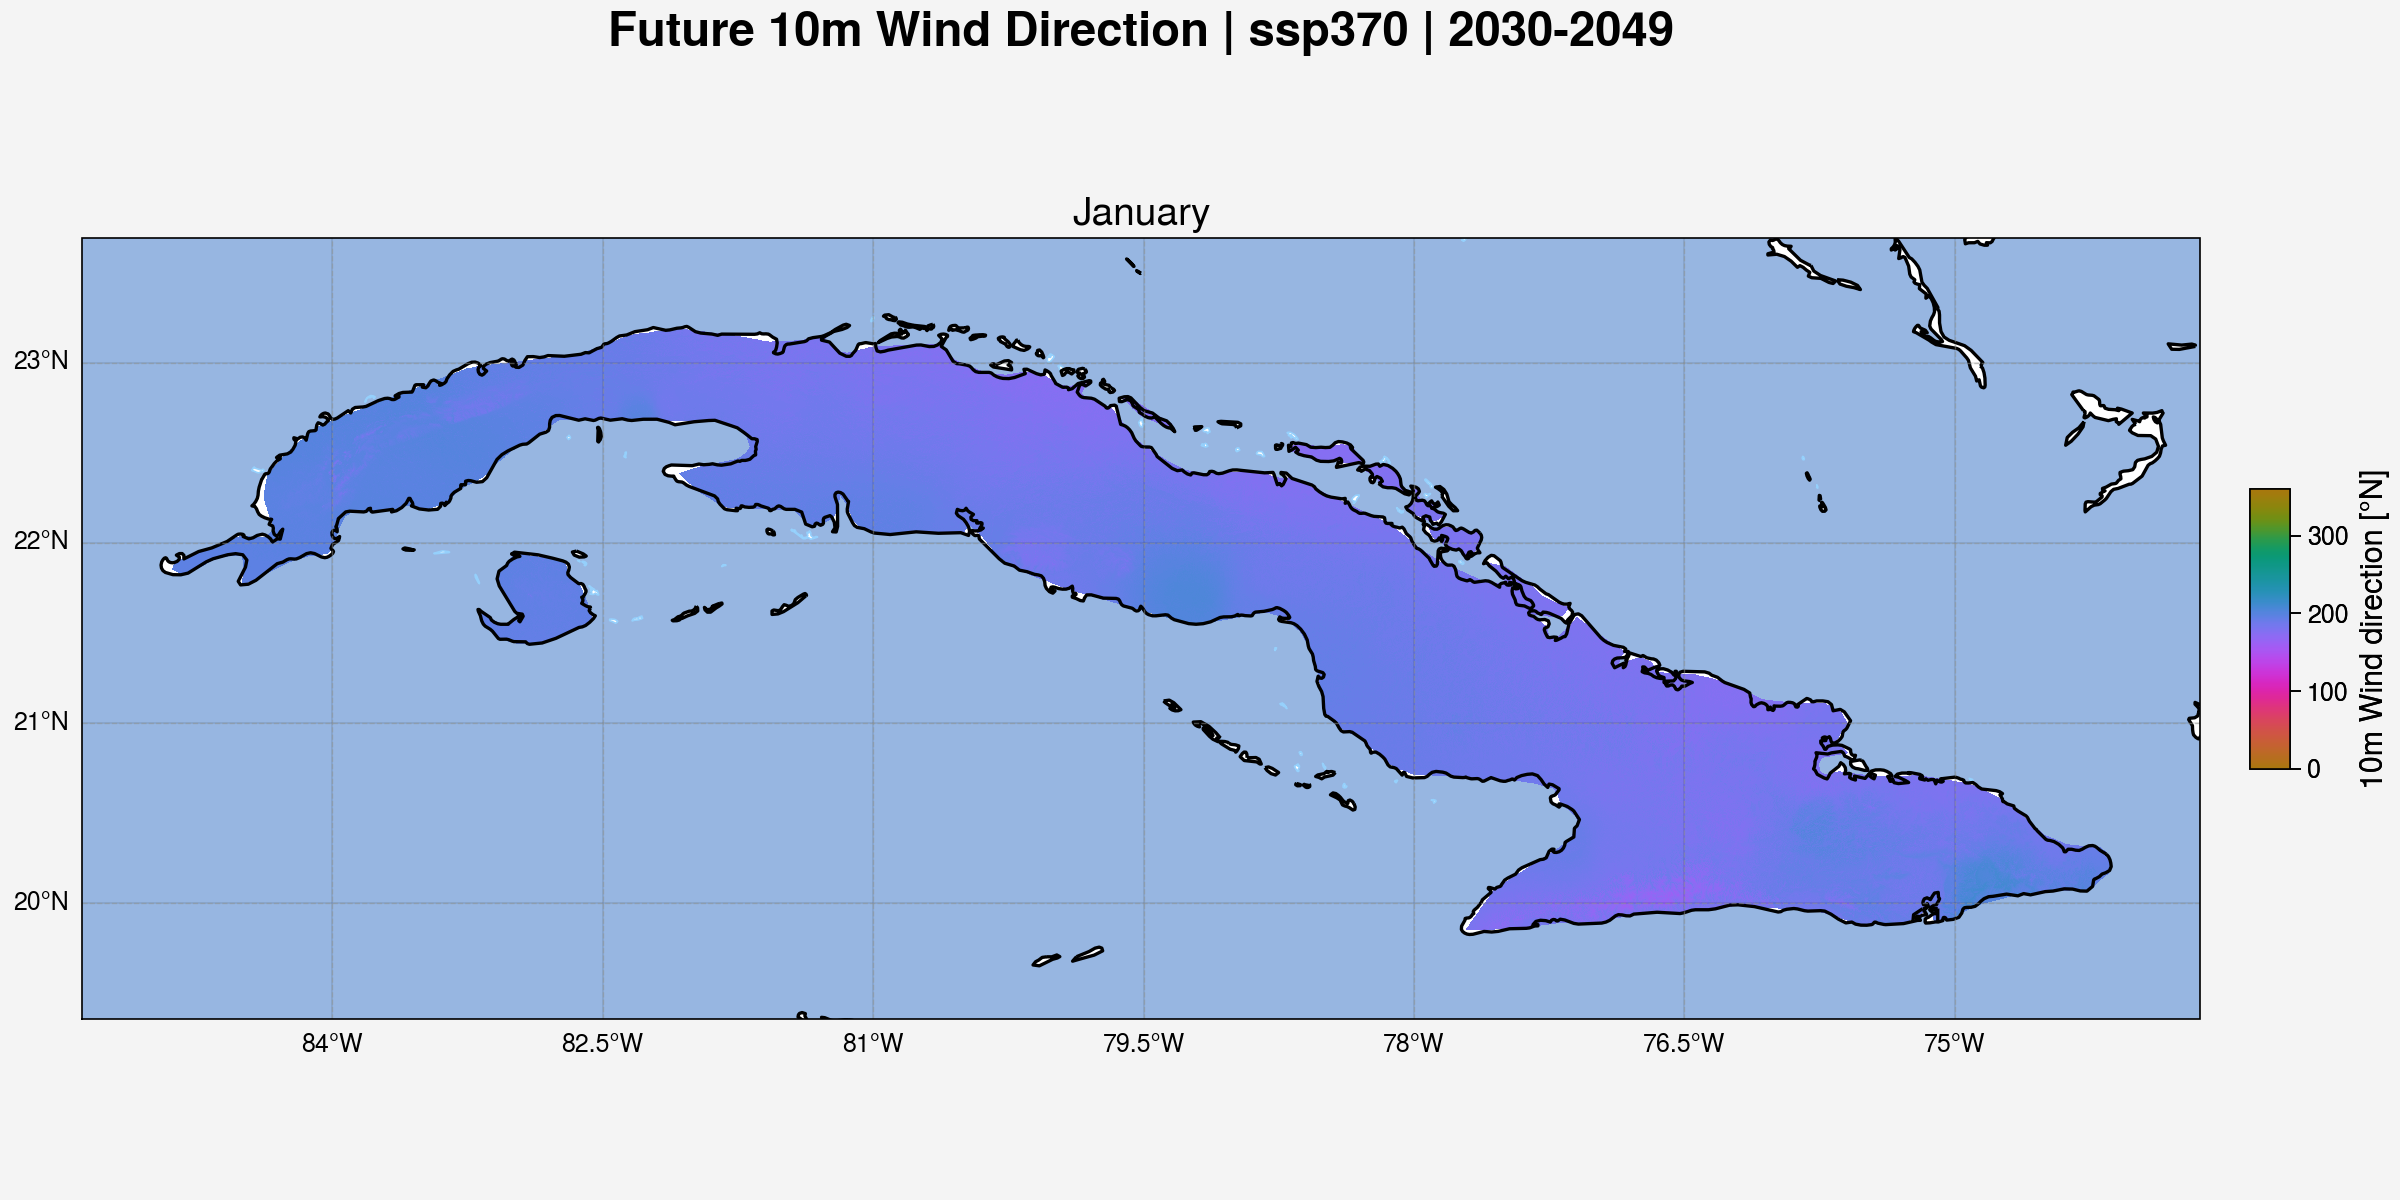

In [11]:
fig, axs = plot.subplots(figsize=(12, 6), subplot_kw={'projection': ccrs.PlateCarree()})

draw_dir(xdf['dir_integrated'], axs, 0, 360, 'Phase', True, '10m Wind direction [°N]', 
     months_names[month-1], f'Future 10m Wind Direction | {exp} | {start}-{end}')
fig.save(f'{output_path}INTEGRATED_rd_{country}_overall_winddir_future_{exp}_m{month}_{start}_{end}.png')

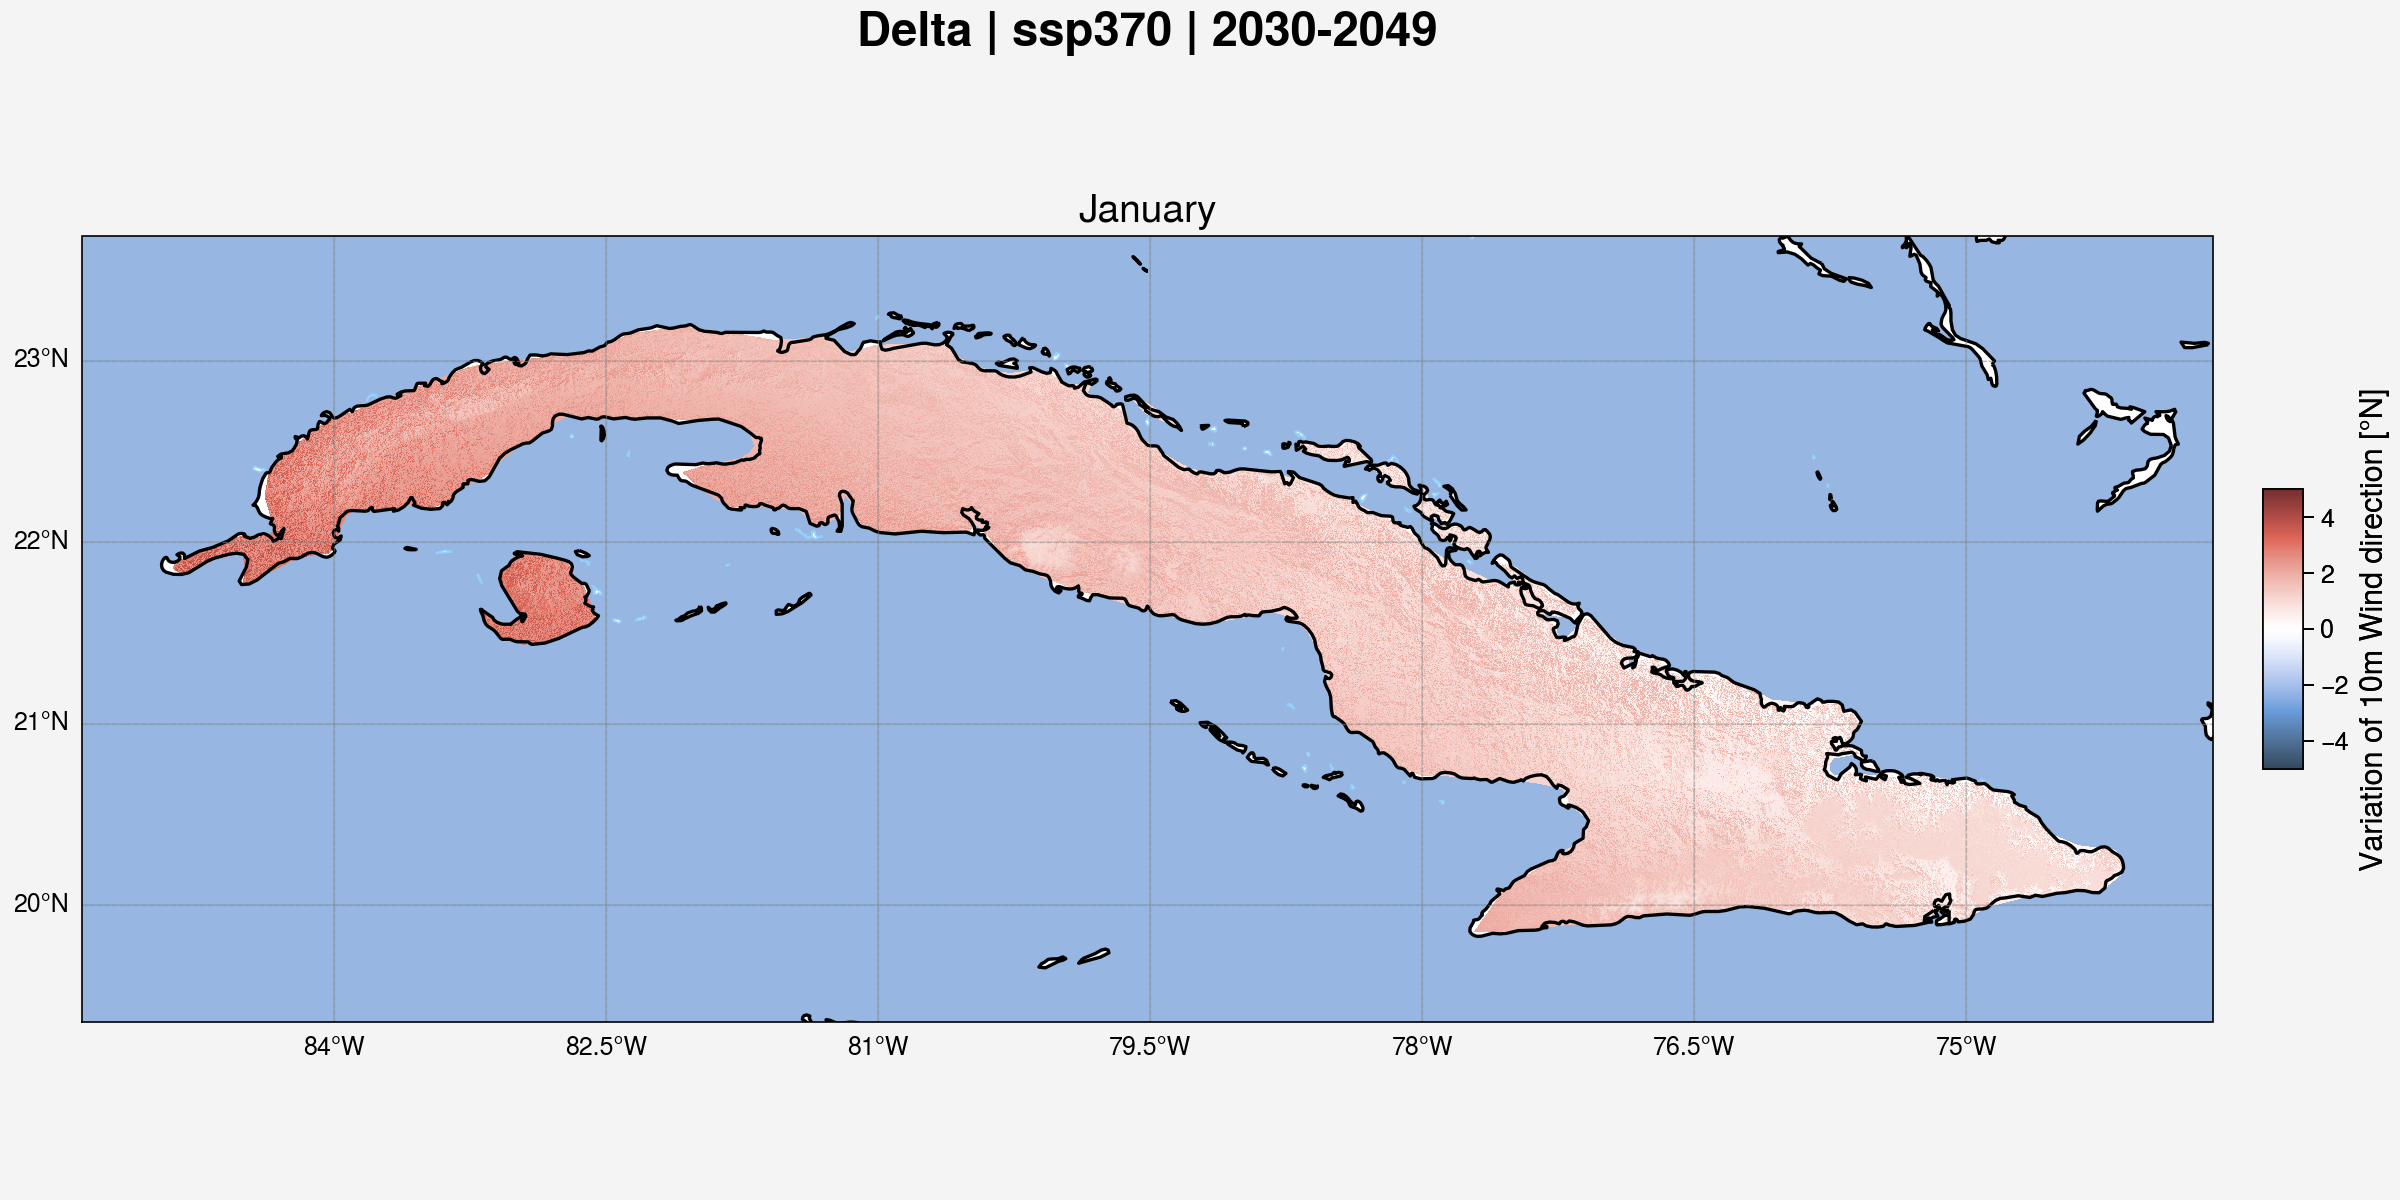

In [12]:
fig, axs = plot.subplots(figsize=(12, 6), subplot_kw={'projection': ccrs.PlateCarree()})

draw_dir(xdf['dir_delta'], axs, -5, 5, 'NegPos', True, 'Variation of 10m Wind direction [°N]', 
     months_names[month-1], f'Delta | {exp} | {start}-{end}')
fig.save(f'{output_path}INTEGRATED_rd_{country}_overall_winddir_delta_{exp}_m{month}_{start}_{end}.png')

### Wind Speed

In [13]:
def draw_speed(xdf, ax, vmin, vmax, cmap, legend=False, label=None, title=None, suptitle=None, orient='vertical'):

    # Add features to the map

    ax.add_feature(cfeature.LAKES, edgecolor='black', facecolor='light blue')
    ax.add_feature(cfeature.OCEAN, edgecolor='light blue')
    ax.add_feature(cfeature.RIVERS, edgecolor='light blue')
    ax.add_feature(cfeature.COASTLINE, edgecolor='black', linewidth=1.2)
    ax.add_feature(cfeature.BORDERS, edgecolor='black', linewidth=1.2)

    xdf.rio.set_spatial_dims(x_dim="longitude", y_dim="latitude", inplace=True)
    xdf.rio.write_crs("epsg:4326", inplace=True)

    cbar_kwargs = {
        'orientation': 'vertical',
        'shrink': 0.25,
        'aspect': 50,
        'pad': 2,
        'label': label,
        'labelsize': 11,
        
    } if legend else None

    #xdf.plot(cmap='reds', ax=ax, vmin=vmin, vmax=vmax)
    im = xr.plot.pcolormesh(xdf, cmap=cmap,ax = ax, 
                        #norm=LogNorm(),
                        vmin=vmin, vmax=vmax,
                        add_colorbar=legend, 
                        add_labels=False, 
                        cbar_kwargs=cbar_kwargs, 
                       )

    if orient == 'horizontal':
        cbar = im.colorbar
        cbar.ax.tick_params(axis='y', rotation=90)
        
    # Add longitude-latitude grid
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
    gl.xlabels_top = False
    gl.ylabels_right = False
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER

    lat_min = np.min(xdf.latitude.values)
    lat_max = np.max(xdf.latitude.values)
    lon_min = np.min(xdf.longitude.values)
    lon_max = np.max(xdf.longitude.values)

    ax.set_extent([lon_min-0.5, lon_max+0.5, lat_min-0.5, lat_max+0.5], crs=ccrs.PlateCarree())
    ax.set_title(title, fontsize=14)
    fig.suptitle(suptitle,fontsize=17)

In [14]:
# Quiver plot of the wind vectors using the scaled components u and v
# To avoid drawing too many arrows, se set the "rate" parameter:
# a rate equal i.e. to 150 draws an arrow every 150 points on the lon,lat grid 
def overlay_quiver(xdf, ax, step, rate=150):
    
    xdf.rio.set_spatial_dims(x_dim="longitude", y_dim="latitude", inplace=True)
    xdf.rio.write_crs("epsg:4326", inplace=True)

    xdf = xdf.rio.clip(geometries)
    
    if step == True:
        ax.quiver(xdf.longitude[::rate], xdf.latitude[::rate], 
                  xdf['u10_integrated'][::rate,::rate], 
                  xdf['v10_integrated'][::rate,::rate],
                  headlength=3, headwidth=3, headaxislength=5)
    else:
        ax.quiver(xdf.longitude, xdf.latitude, 
                  xdf['u10_integrated'], xdf['v10_integrated'],
                  headlength=5, headwidth=3, headaxislength=5)

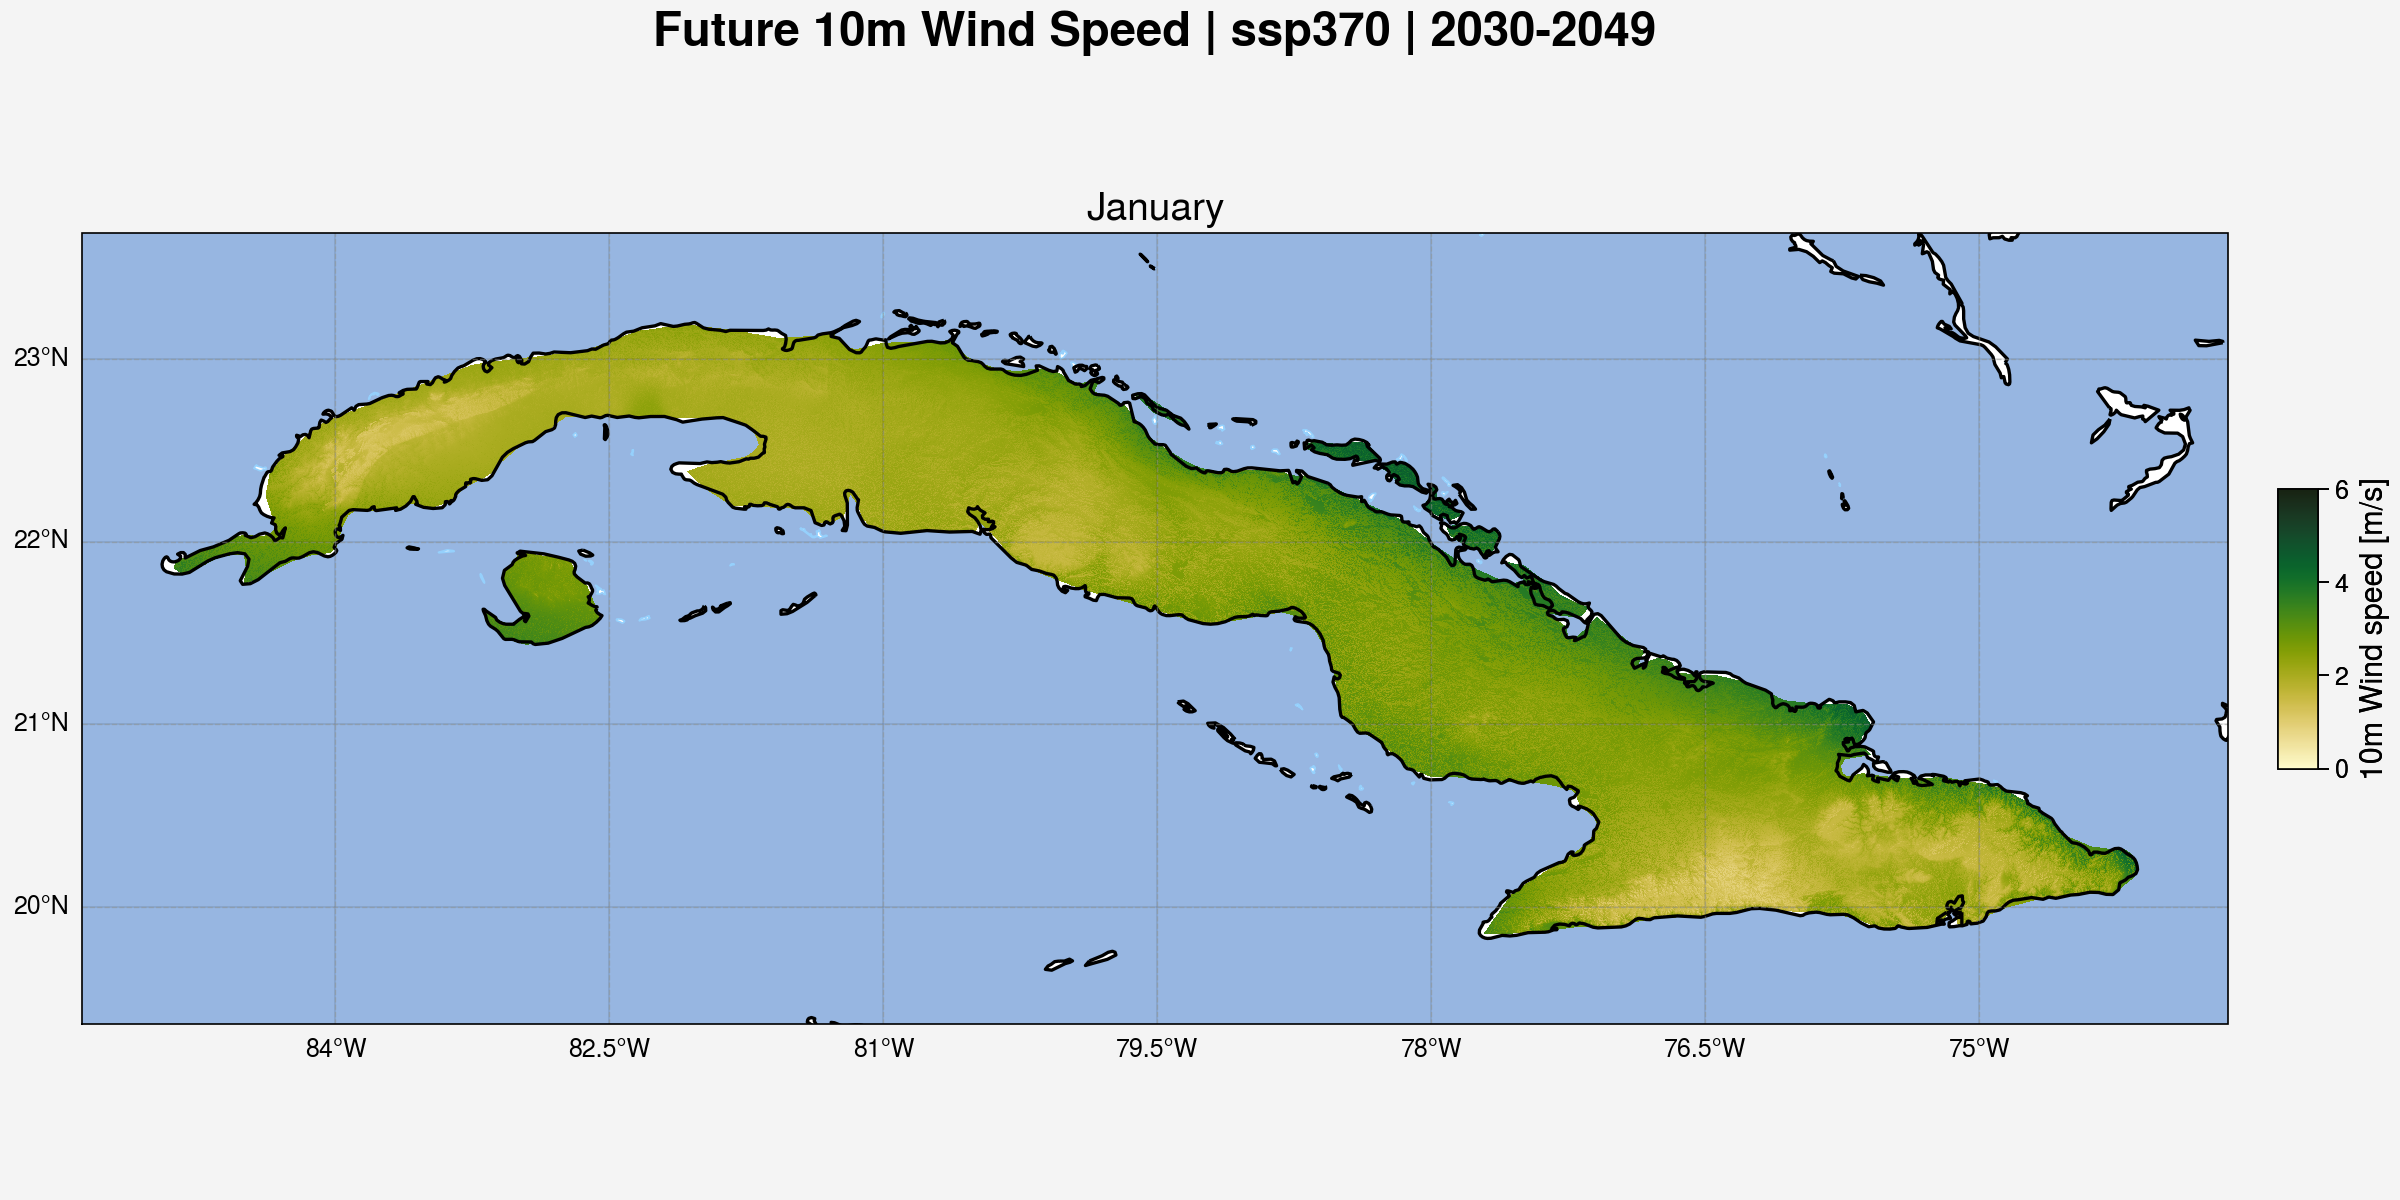

In [15]:
fig, axs = plot.subplots(figsize=(12, 6), subplot_kw={'projection': ccrs.PlateCarree()})

draw_speed(xdf['wds_integrated'], axs, 0, 6,'Speed', True, '10m Wind speed [m/s]', 
         months_names[month-1], f'Future 10m Wind Speed | {exp} | {start}-{end}')
#overlay_quiver(xdf, axs, step = True)
fig.save(f'{output_path}INTEGRATED_rd_{country}_overall_windspeed_future_{exp}_m{month}_{start}_{end}.png')

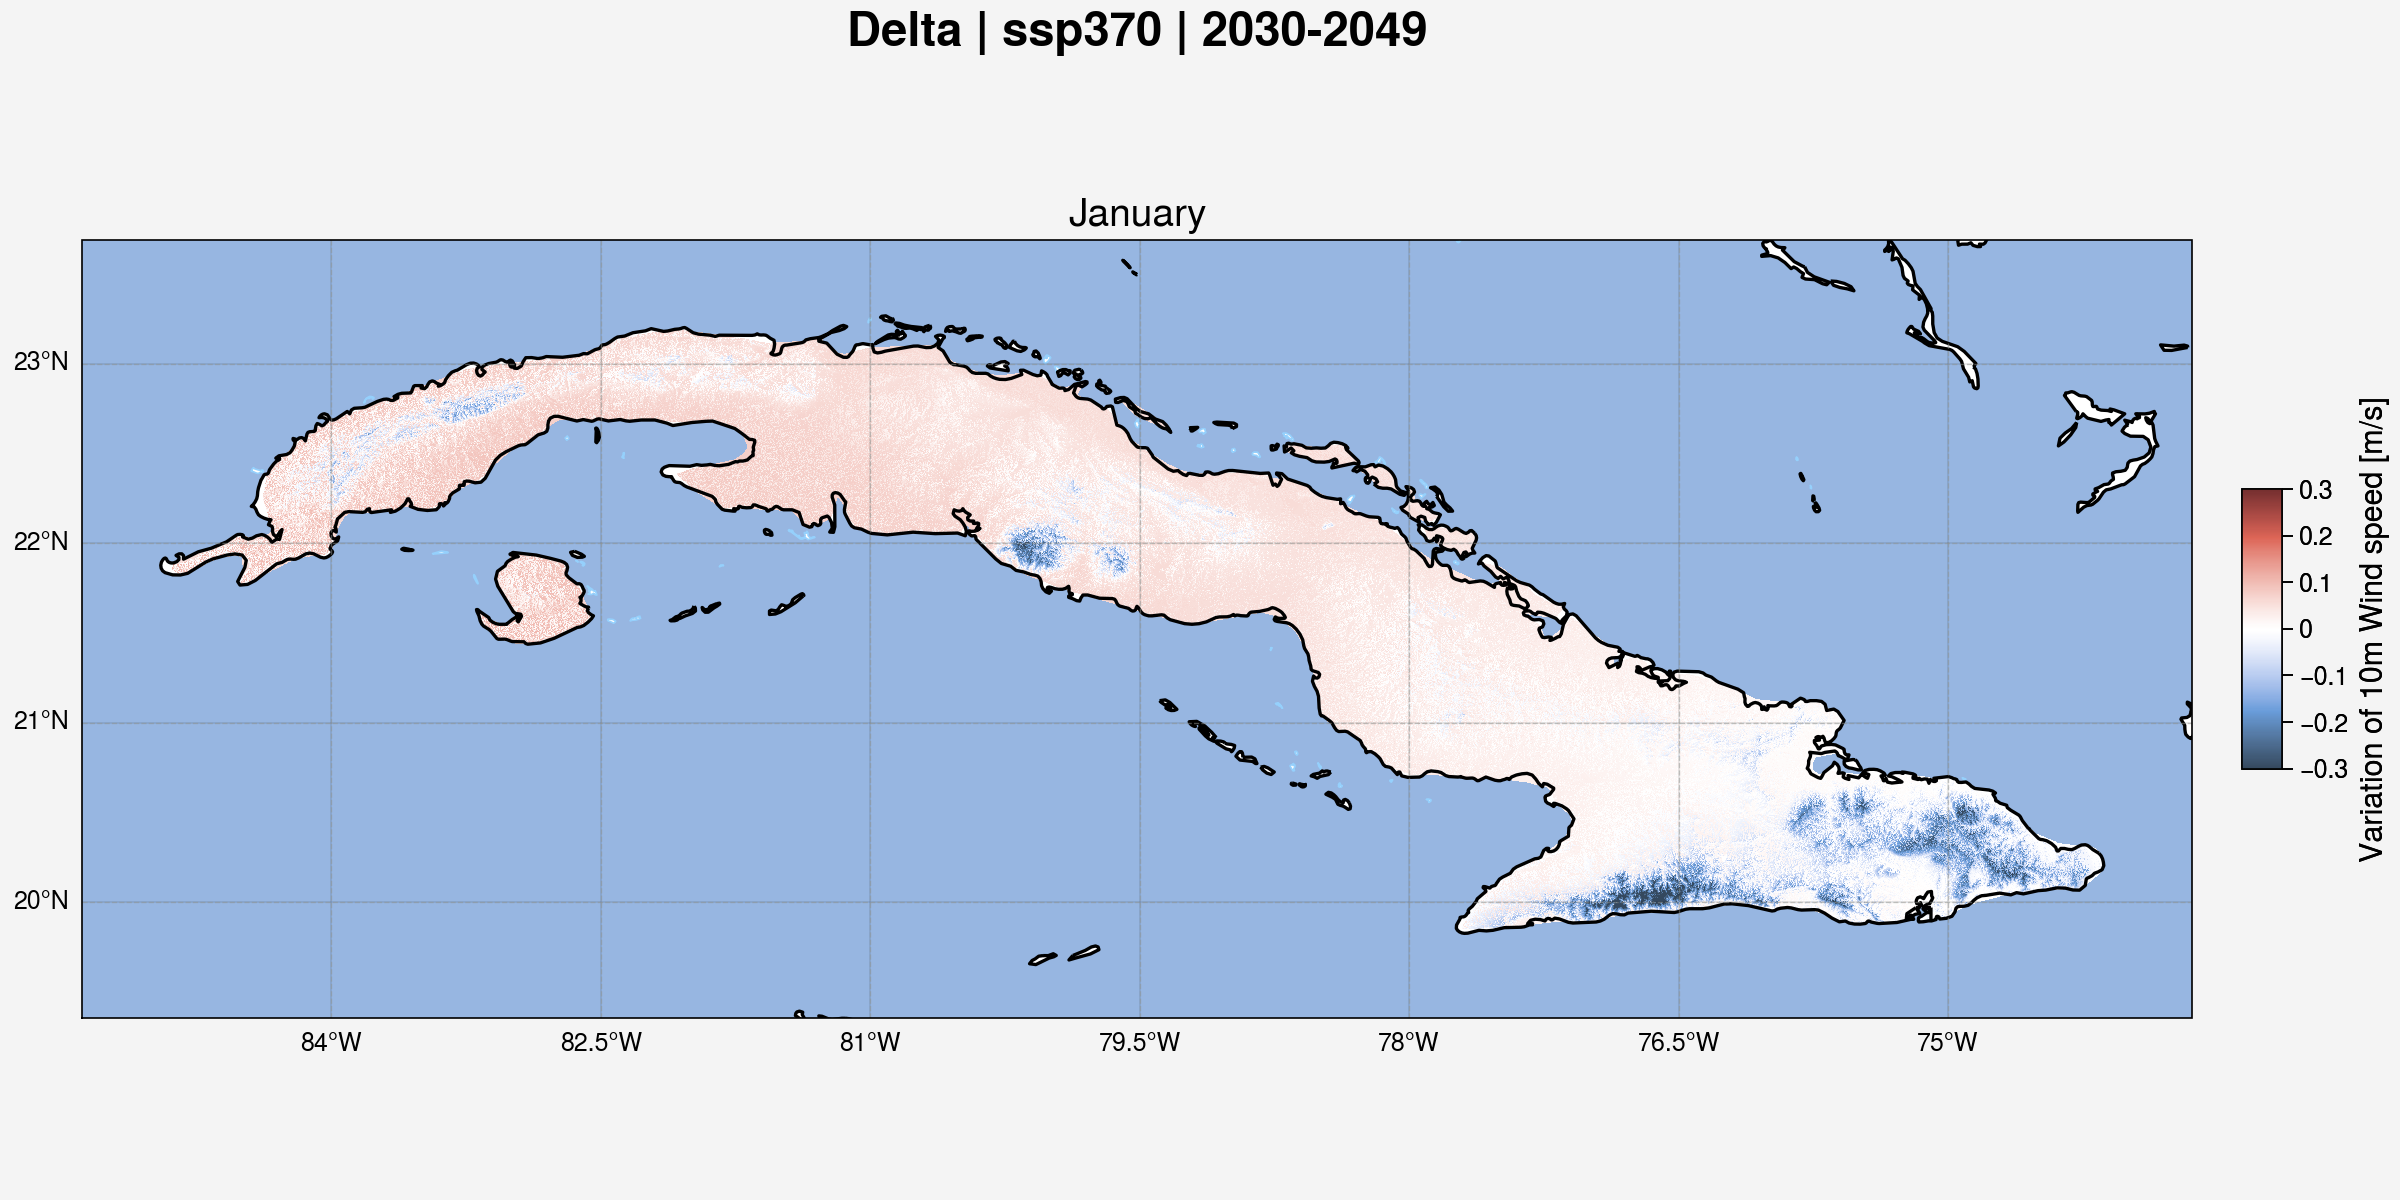

In [16]:
fig, axs = plot.subplots(figsize=(12, 6), subplot_kw={'projection': ccrs.PlateCarree()})

draw_speed(xdf['wds_delta'], axs, -0.3, 0.3,'NegPos', True, 'Variation of 10m Wind speed [m/s]', 
         months_names[month-1], f'Delta | {exp} | {start}-{end}')
fig.save(f'{output_path}INTEGRATED_rd_{country}_overall_windspeed_delta_{exp}_m{month}_{start}_{end}.png')